# Quiz 3：模型表現評估 — ROC 與 AUC

**對應講義：第 75 頁；涵蓋基礎與進階。**

直接延續 Quiz 2 的信用卡資料、`Improved MLP` 及精確相同的 train／validation 切分。
第二個模型使用講義第 31 頁列出的 **Random Forest**。

1. 讀取 Quiz 2 的縮放資料、索引、驗證標籤與 MLP 機率。
2. 畫 MLP 的 ROC，X 軸是 FPR、Y 軸是 TPR，圖例標示 AUC。
3. 在同一訓練集訓練 Random Forest，取正類機率。
4. 把兩條 ROC 疊在同一張圖，計算並比較 AUC。

壓縮檔已附 Quiz 2 執行產生的 artifacts，可直接開本題。
若你重跑 Quiz 2，請也重跑 Quiz 3；程式會讀取更新後的同一批資料與機率。
AI 協作紀錄：ChatGPT／Codex 協助程式與解釋；AUC 與比較結論由實際執行產生。

## 1. 子目標：讀取 Quiz 2 的成果
不重新 `train_test_split`，也不重新 fit scaler。使用 `.npz` 可直接保存並讀取數值陣列。
檢查資料 SHA-256、客戶 ID、驗證索引與標籤，避免誤讀另一版本的輸出。

In [1]:
# 子目標：找到 HW2 根目錄，讓本機 Jupyter、VS Code 與 Colab 使用同一份路徑設定。
from pathlib import Path
import os
import random
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

if os.environ.get("HW2_ROOT"):
    ROOT = Path(os.environ["HW2_ROOT"]).expanduser().resolve()
else:
    candidates = [Path.cwd(), Path.cwd() / "HW2", Path.cwd() / "output" / "HW2"]
    ROOT = next((p for p in candidates if (p / "data" / "UCI_Credit_Card.csv").is_file()), None)
    if ROOT is None:
        raise FileNotFoundError("找不到 HW2。請從解壓後的 HW2 開啟 Notebook；Colab 設 HW2_ROOT=/content/HW2。")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
print("HW2:", ROOT)
print("random seed:", SEED)

# 子目標：讀取共享切分與 MLP 的連續預測機率。
ART = ROOT / "artifacts" / "quiz2"
OUT = ROOT / "results" / "quiz3"
OUT.mkdir(parents=True, exist_ok=True)
required = [ART / "credit_split.npz", ART / "mlp_validation_predictions.npz", ART / "metadata.json"]
if not all(p.is_file() for p in required):
    raise FileNotFoundError("請先從上到下完整執行 Quiz2_Credit_Default_MLP.ipynb，再執行 Quiz 3。")
metadata = json.loads((ART / "metadata.json").read_text(encoding="utf-8"))
with np.load(ART / "credit_split.npz", allow_pickle=False) as saved:
    split = {key: saved[key].copy() for key in saved.files}
with np.load(ART / "mlp_validation_predictions.npz", allow_pickle=False) as saved:
    predictions = {key: saved[key].copy() for key in saved.files}
X_train, X_val = split["X_train"], split["X_val"]
y_train, y_val = split["y_train"], split["y_val"]
mlp_probability = predictions["improved_probability"]
current_sha = hashlib.sha256((ROOT / "data" / "UCI_Credit_Card.csv").read_bytes()).hexdigest()
assert current_sha == split["data_sha256"].item() == predictions["data_sha256"].item() == metadata["dataset_sha256"]
np.testing.assert_array_equal(split["val_idx"], predictions["val_idx"])
np.testing.assert_array_equal(split["val_ids"], predictions["val_ids"])
np.testing.assert_array_equal(y_val, predictions["y_val"])
assert not set(split["train_idx"]) & set(split["val_idx"])
raw_df = pd.read_csv(ROOT / "data" / "UCI_Credit_Card.csv")
np.testing.assert_array_equal(y_train, raw_df[metadata["target"]].to_numpy()[split["train_idx"]])
np.testing.assert_array_equal(y_val, raw_df[metadata["target"]].to_numpy()[split["val_idx"]])
np.testing.assert_array_equal(split["val_ids"], raw_df["ID"].to_numpy()[split["val_idx"]])
print("Same Quiz 2 split:", X_train.shape, X_val.shape)
print("MLP: Improved MLP / best epoch", metadata["best_epochs"]["Improved MLP"])
print("Positive class = 1 (default); using probabilities, not 0/1 predictions.")

HW2: /workspace/scratch/70c916837713/output/HW2
random seed: 42
Same Quiz 2 split: (24000, 23) (6000, 23)
MLP: Improved MLP / best epoch 53
Positive class = 1 (default); using probabilities, not 0/1 predictions.


## 2. 子目標：理解 ROC 與 AUC

| 指標 | 定義與意義 |
|---|---|
| FPR | `FP / (FP + TN)`：真正未違約的人中，被誤判違約的比例 |
| TPR | `TP / (TP + FN)`，也就是 Recall：真正違約的人中，被抓到的比例 |
| ROC | 掃描不同門檻，把每個門檻的 `(FPR, TPR)` 畫出來 |
| AUC | ROC 下的面積；可解讀為隨機挑一正一負樣本，正類分數較高的機率，平手計半分 |

曲線越接近左上角，通常表示越低的誤報率能達到越高的 Recall。
AUC 約 0.5 表示接近隨機排序，1 表示完全區分；AUC **不是 Accuracy**，也不評估機率校準。
必須使用機率／連續分數畫 ROC，不能先把機率用 0.50 切成 0／1。

## 3. 主目標：MLP 的 ROC 與 AUC
使用第二題保存的 Improved MLP 機率，圖例清楚標示 AUC。

MLP ROC AUC = 0.772270


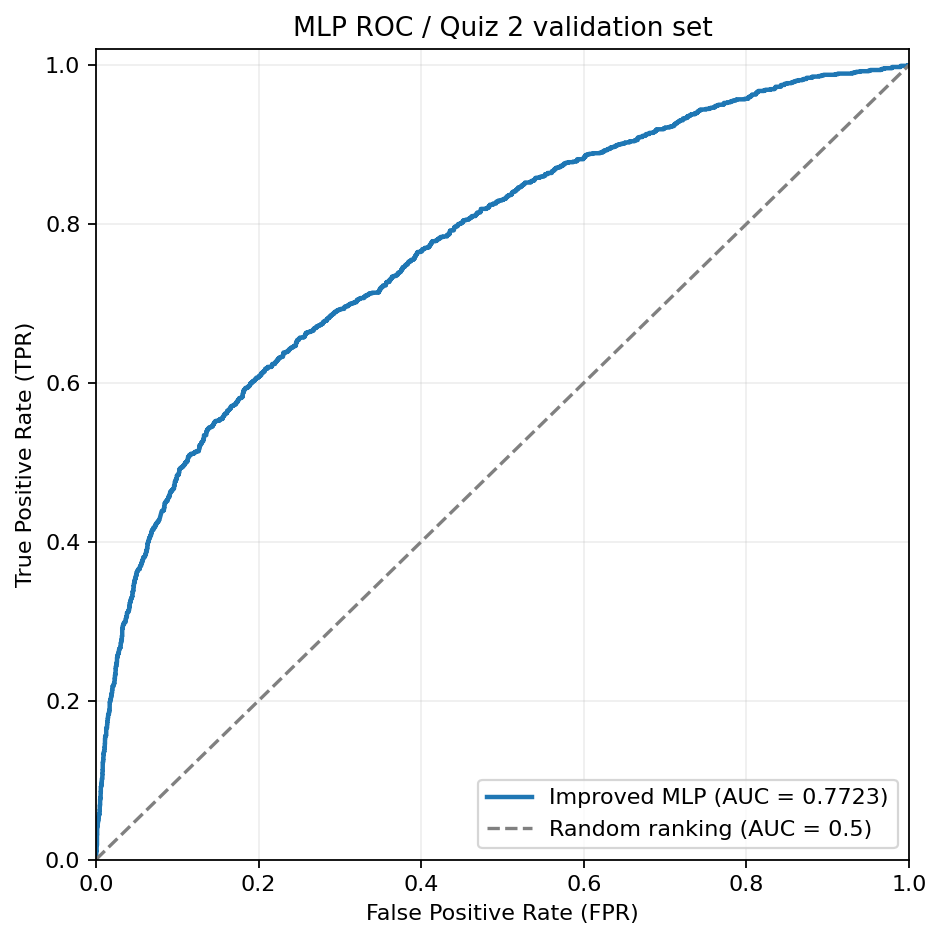

In [2]:
# 主目標：計算 MLP 的 FPR／TPR／AUC 並繪圖。
from sklearn.metrics import roc_curve, roc_auc_score
mlp_fpr, mlp_tpr, mlp_thresholds = roc_curve(y_val, mlp_probability, pos_label=1)
mlp_auc = float(roc_auc_score(y_val, mlp_probability))
pd.DataFrame({"FPR": mlp_fpr, "TPR": mlp_tpr, "Threshold": mlp_thresholds}).to_csv(OUT / "mlp_roc_points.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(mlp_fpr, mlp_tpr, lw=2, label=f"Improved MLP (AUC = {mlp_auc:.4f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Random ranking (AUC = 0.5)")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="False Positive Rate (FPR)",
       ylabel="True Positive Rate (TPR)", title="MLP ROC / Quiz 2 validation set")
ax.legend(loc="lower right"); ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / "mlp_roc.png", dpi=160, bbox_inches="tight")
plt.show(); plt.close(fig)
print(f"MLP ROC AUC = {mlp_auc:.6f}")

## 4. 主目標：使用相同 Training Dataset 建立 Random Forest
Random Forest 是多棵決策樹的集成，屬於講義介紹的機器學習分類算法。
使用 300 棵樹、深度上限 12、每葉至少 10 筆，seed=42。
直接使用 Quiz 2 的 23 欄縮放資料。樹模型通常不需要縮放，此處沿用縮放資料確保流程一致。
所有超參數事先固定，不用這次驗證集選參數。

In [3]:
# 主目標：訓練課程中的 Random Forest 並取得正類機率。
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=300, max_depth=12,
    min_samples_leaf=10, random_state=SEED, n_jobs=2)
rf.fit(X_train, y_train)
positive_column = int(np.flatnonzero(rf.classes_ == 1)[0])
rf_probability = rf.predict_proba(X_val)[:, positive_column]
rf_fpr, rf_tpr, rf_thresholds = roc_curve(y_val, rf_probability, pos_label=1)
rf_auc = float(roc_auc_score(y_val, rf_probability))
pd.DataFrame({"FPR": rf_fpr, "TPR": rf_tpr, "Threshold": rf_thresholds}).to_csv(OUT / "rf_roc_points.csv", index=False)
pd.DataFrame({"ClientID": split["val_ids"], "ValidationRowIndex": split["val_idx"],
    "TrueLabel": y_val, "MLPProbability": mlp_probability,
    "RandomForestProbability": rf_probability}).to_csv(OUT / "validation_predictions.csv", index=False)
print(f"Random Forest ROC AUC = {rf_auc:.6f}")
display(pd.DataFrame({"Feature": split["feature_names"], "Importance": rf.feature_importances_})
    .sort_values("Importance", ascending=False).head(10))

Random Forest ROC AUC = 0.776077


,Feature,Importance
5,PAY_0,0.260733
6,PAY_2,0.106469
7,PAY_3,0.055839
8,PAY_4,0.052047
9,PAY_5,0.044332
10,PAY_6,0.041322
17,PAY_AMT1,0.041040
0,LIMIT_BAL,0.039913
11,BILL_AMT1,0.035892
18,PAY_AMT2,0.033467


## 5. 主目標：將兩條 ROC 疊在同一張圖
兩個模型評估的是相同 6,000 筆、相同正負標籤的驗證資料。
圖中兩條曲線分別標示模型名稱與 AUC。

,Model,ROC_AUC,ValidationSamples
0,Improved MLP (Quiz 2),0.77227,6000
1,Random Forest,0.77608,6000


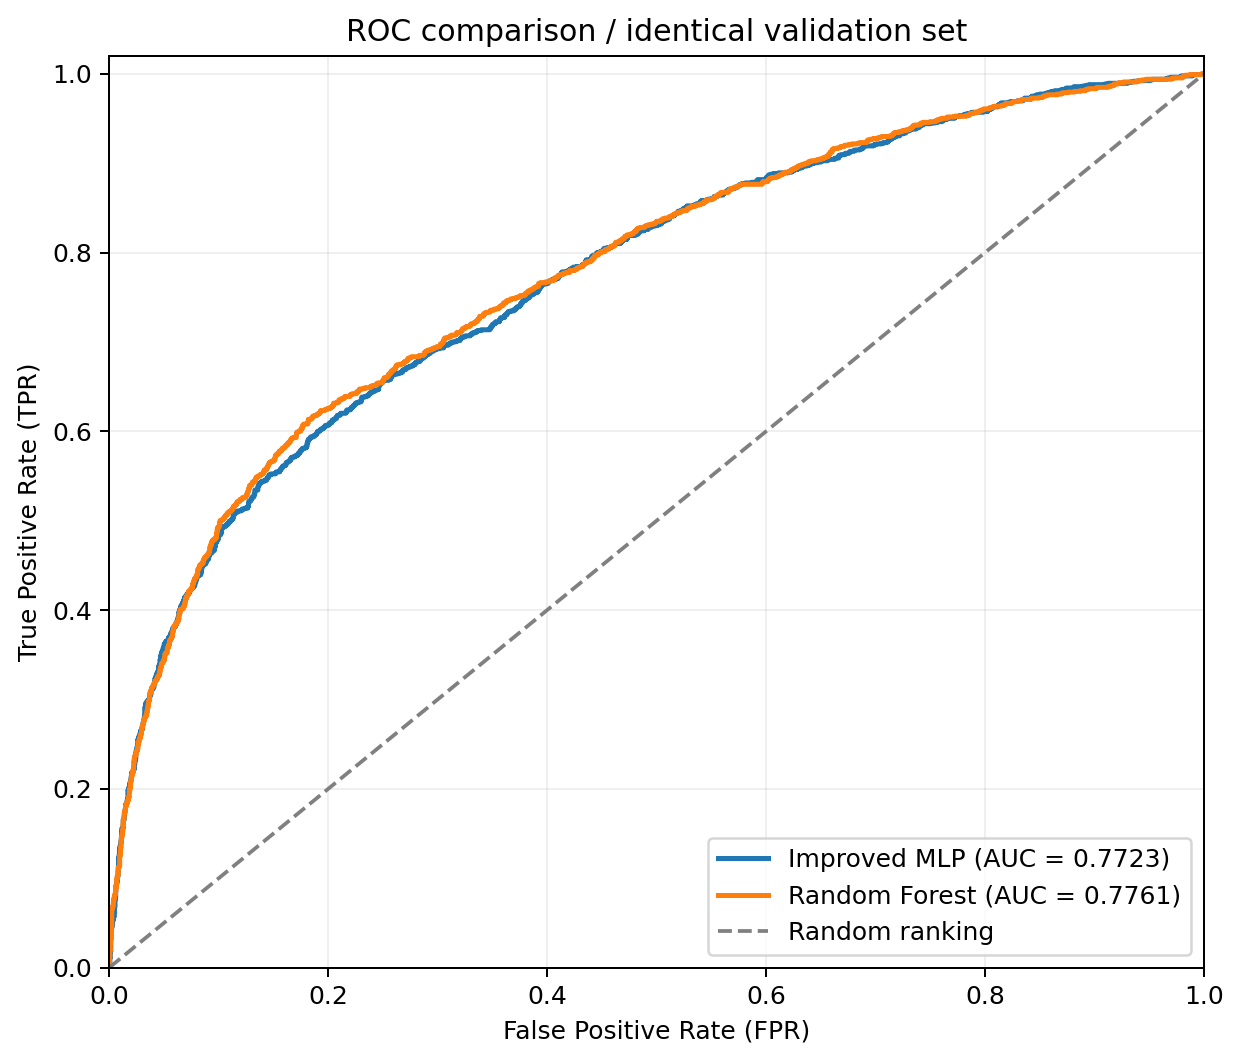

In [4]:
# 主目標：同圖比較 ROC，保存兩模型的 AUC。
auc_table = pd.DataFrame([
    {"Model": "Improved MLP (Quiz 2)", "ROC_AUC": mlp_auc, "ValidationSamples": len(y_val)},
    {"Model": "Random Forest", "ROC_AUC": rf_auc, "ValidationSamples": len(y_val)},
])
auc_table.to_csv(OUT / "auc_comparison.csv", index=False)
display(auc_table.round(5))
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(mlp_fpr, mlp_tpr, lw=2, label=f"Improved MLP (AUC = {mlp_auc:.4f})")
ax.plot(rf_fpr, rf_tpr, lw=2, label=f"Random Forest (AUC = {rf_auc:.4f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="False Positive Rate (FPR)",
       ylabel="True Positive Rate (TPR)", title="ROC comparison / identical validation set")
ax.legend(loc="lower right"); ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / "roc_comparison.png", dpi=180, bbox_inches="tight")
plt.show(); plt.close(fig)

## 6. 主目標：比較正負樣本區分能力
先比較整體 AUC，再比較幾個固定 FPR 上限所能達到的最高 TPR。
曲線若互相交叉，整體 AUC 較高並不代表每一個操作區域都較好。

In [5]:
# 主目標：依實際 AUC 與 ROC 撰寫比較，避免宣稱全面勝出。
delta = rf_auc - mlp_auc
winner = "Random Forest" if delta > 0 else "Improved MLP" if delta < 0 else "兩者相同"
operating_rows = []
for cap in [0.05, 0.10, 0.20]:
    for name, fpr, tpr in [("Improved MLP", mlp_fpr, mlp_tpr), ("Random Forest", rf_fpr, rf_tpr)]:
        operating_rows.append({"Model": name, "FPR upper bound": cap,
            "Max TPR at or below bound": float(tpr[fpr <= cap].max())})
operating_df = pd.DataFrame(operating_rows)
display(operating_df.round(4))
operating_df.to_csv(OUT / "roc_operating_points.csv", index=False)
report = (
    f"### 實測觀察\n"
    f"- Improved MLP AUC = **{mlp_auc:.5f}**；Random Forest AUC = **{rf_auc:.5f}**。\n"
    f"- Random Forest − MLP 的 AUC 差值 = **{delta:+.5f}**；本次驗證集的整體 AUC 較高者為 **{winner}**。\n"
    "- AUC 較高表示這次驗證集的整體正負排序區分能力較佳；不代表每一個門檻的 Precision、Recall 都較佳。\n"
    "- 固定 FPR 上限的 TPR 表提供局部操作區域的比較；實際門檻仍需依誤報／漏報代價另行決定。\n"
    "- MLP 的 checkpoint 由本驗證集挑選；Random Forest 參數事先固定。這是作業的驗證比較，並非獨立測試或統計顯著性結論。\n"
)
display(Markdown(report))
_ = (OUT / "observations.md").write_text(report, encoding="utf-8")

,Model,FPR upper bound,Max TPR at or below bound
0,Improved MLP,0.05,0.3595
1,Random Forest,0.05,0.3436
2,Improved MLP,0.10,0.4838
3,Random Forest,0.10,0.4936
4,Improved MLP,0.20,0.6074
5,Random Forest,0.20,0.6255


### 實測觀察
- Improved MLP AUC = **0.77227**；Random Forest AUC = **0.77608**。
- Random Forest − MLP 的 AUC 差值 = **+0.00381**；本次驗證集的整體 AUC 較高者為 **Random Forest**。
- AUC 較高表示這次驗證集的整體正負排序區分能力較佳；不代表每一個門檻的 Precision、Recall 都較佳。
- 固定 FPR 上限的 TPR 表提供局部操作區域的比較；實際門檻仍需依誤報／漏報代價另行決定。
- MLP 的 checkpoint 由本驗證集挑選；Random Forest 參數事先固定。這是作業的驗證比較，並非獨立測試或統計顯著性結論。


## 7. 測試：核對跨題一致性與 ROC 正確性
確認沒有重新切資料、機率不是硬標籤、ROC 軸定義正確，且 AUC 與保存的表一致。

In [6]:
# 測試：確認兩模型使用相同的樣本，且 ROC／AUC 計算有效。
assert X_train.shape == (24000, 23) and X_val.shape == (6000, 23)
assert metadata["configs"]["Improved MLP"]["epochs"] >= 50
for probability in [mlp_probability, rf_probability]:
    assert probability.shape == y_val.shape
    assert np.isfinite(probability).all() and ((probability >= 0) & (probability <= 1)).all()
    assert np.unique(probability).size > 2
for fpr, tpr, auc in [(mlp_fpr, mlp_tpr, mlp_auc), (rf_fpr, rf_tpr, rf_auc)]:
    assert 0 <= auc <= 1 and np.all(np.diff(fpr) >= 0) and np.all(np.diff(tpr) >= 0)
    assert fpr[0] == tpr[0] == 0 and fpr[-1] == tpr[-1] == 1
np.testing.assert_array_equal(predictions["val_idx"], split["val_idx"])
assert np.isclose(auc_table.loc[0, "ROC_AUC"], roc_auc_score(y_val, mlp_probability))
assert np.isclose(auc_table.loc[1, "ROC_AUC"], roc_auc_score(y_val, rf_probability))
print("PASS：同一 train／validation 切分、連續機率、單模型及雙模型 ROC、圖中 AUC 與比較結論均完成。")

PASS：同一 train／validation 切分、連續機率、單模型及雙模型 ROC、圖中 AUC 與比較結論均完成。
